In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tir_reader import load_tir
import tyre_model as tm

tyre = load_tir("data/sample.tir")


def axle_peak_force(tyre, Fz_static, dFz):
    alpha = np.radians(np.linspace(0, 20, 2001))
    Fz_outer = min(Fz_static + dFz, 2 * Fz_static)
    Fz_inner = Fz_static - dFz

    Fy_axle = -tm.lateral_force(tyre, alpha, Fz_outer)
    if Fz_inner > 0:
        Fy_axle = Fy_axle - tm.lateral_force(tyre, alpha, Fz_inner)

    i = np.argmax(Fy_axle)
    return Fy_axle[i], np.degrees(alpha[i])


print(axle_peak_force(tyre, 4000, 0))
print(axle_peak_force(tyre, 4000, 2000))

(np.float64(7080.879966594171), np.float64(9.370000000000001))
(np.float64(6869.016384873845), np.float64(10.53))


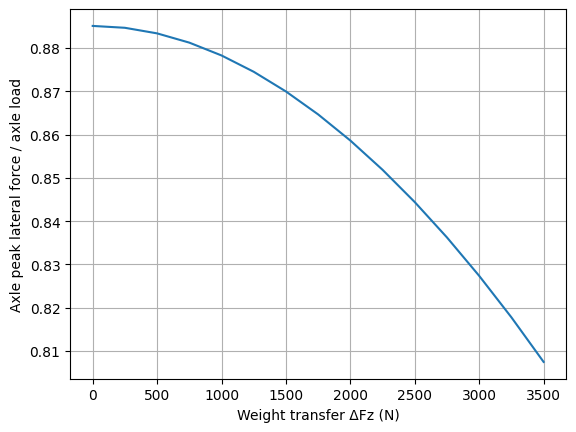

In [3]:
transfers = np.linspace(0, 3500, 15)
peaks = []

for dFz in transfers:
    peak, angle = axle_peak_force(tyre, 4000, dFz)
    peaks.append(peak)

peaks = np.array(peaks)

plt.plot(transfers, peaks / 8000)
plt.xlabel("Weight transfer ΔFz (N)")
plt.ylabel("Axle peak lateral force / axle load")
plt.grid(True)
plt.show()

In [4]:
def car_balance(tyre, mass, front_weight_share, cg_height, track,
                front_roll_share, ay_g=1.0):
    W = mass * 9.81

    # static load on one tyre at each end
    Fz_front = W * front_weight_share / 2
    Fz_rear = W * (1 - front_weight_share) / 2

    # total weight transfer, split by roll stiffness
    dFz_total = W * ay_g * cg_height / track
    dFz_front = front_roll_share * dFz_total
    dFz_rear = (1 - front_roll_share) * dFz_total

    # each axle's grip per newton of axle load
    front_peak, _ = axle_peak_force(tyre, Fz_front, dFz_front)
    rear_peak, _ = axle_peak_force(tyre, Fz_rear, dFz_rear)
    mu_front = front_peak / (2 * Fz_front)
    mu_rear = rear_peak / (2 * Fz_rear)

    return mu_front, mu_rear


print(car_balance(tyre, 1631, 0.5, 0.5, 1.5, 0.6))
print(car_balance(tyre, 1631, 0.6, 0.5, 1.5, 0.5))

(np.float64(0.819760496534382), np.float64(0.8551115415433683))
(np.float64(0.8250456802723043), np.float64(0.8490430510121916))


In [5]:
for share in np.linspace(0.3, 0.7, 9):
    mu_f, mu_r = car_balance(tyre, 1631, 0.6, 0.5, 1.5, share)
    print(round(share, 2), round(mu_f, 3), round(mu_r, 3))

0.3 0.85 0.825
0.35 0.845 0.825
0.4 0.839 0.825
0.45 0.832 0.837
0.5 0.825 0.849
0.55 0.817 0.86
0.6 0.809 0.869
0.65 0.8 0.877
0.7 0.79 0.885


In [6]:
def max_lateral_g(tyre, mass, front_weight_share, cg_height, track,
                  front_roll_share, verbose=False):
    ay = 1.0
    for step in range(50):
        mu_f, mu_r = car_balance(tyre, mass, front_weight_share, cg_height,
                                 track, front_roll_share, ay)
        new_ay = min(mu_f, mu_r)
        if verbose:
            print(step, round(ay, 4), round(mu_f, 4), round(mu_r, 4))
        if abs(new_ay - ay) < 1e-4:
            return new_ay, mu_f, mu_r
        ay = new_ay
    raise RuntimeError("Did not converge")


print(max_lateral_g(tyre, 1631, 0.5, 0.5, 1.5, 0.6, verbose=True))

0 1.0 0.8198 0.8551
1 0.8198 0.8405 0.8647
2 0.8405 0.8383 0.8637
3 0.8383 0.8385 0.8638
4 0.8385 0.8385 0.8638
(np.float64(0.8384888265280638), np.float64(0.8384888265280638), np.float64(0.8637738040070064))


In [7]:
print("50/50 car, front takes 60%:", max_lateral_g(tyre, 1631, 0.5, 0.5, 1.5, 0.6)[0])
print("50/50 car, even split:     ", max_lateral_g(tyre, 1631, 0.5, 0.5, 1.5, 0.5)[0])
print("60/40 car, even split:     ", max_lateral_g(tyre, 1631, 0.6, 0.5, 1.5, 0.5)[0])
print("60/40 car, front takes 44%:", max_lateral_g(tyre, 1631, 0.6, 0.5, 1.5, 0.44)[0])

for h in [0.3, 0.4, 0.5, 0.6]:
    print("CG height", h, "m:", max_lateral_g(tyre, 1631, 0.5, h, 1.5, 0.5)[0])

50/50 car, front takes 60%: 0.8384888265280638
50/50 car, even split:      0.8513009611924363
60/40 car, even split:      0.8364699120944431
60/40 car, front takes 44%: 0.8423257581526634
CG height 0.3 m: 0.871968150367883
CG height 0.4 m: 0.8625713321642205
CG height 0.5 m: 0.8513009611924363
CG height 0.6 m: 0.8384888265280638
